In [1]:
### IMPORTS
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi
from voronoi_tesselation import get_polygons_properties_2d, voronoi_finite_polygons_2d, voronoi_plot_2d
from voronoi_tesselation import generate_periodic_voronoi_cells_2
from voronoi_tesselation import plot_polygons
import numpy as np
import plot_ellipses_test as pet
from matplotlib.patches import Ellipse
from ellipse_fitting_polygon import initialization

In [2]:
def compute_moment_tensors_full(regions, vertices, points, areas):
    """
    Compute a moment tensor for every cell (simple polygons, 0th, 1st and 2nd moments)
    Based on Mulchrone and Choudhury, J. of Structural Geology 26 (2004)
    
    Parameters:
    -----
    regions : numpy array 
        Array of arrays pointing to the "vertices" array, determining a cell
    vertices : numpy array
        Coordinates of cell vertices
    points : numpy array
        Coordinates of Voronoi centers
    areas : numpy array
        Areas of Voronoi cells
    Returns:
    -----
    moment_tensors : numpy array 
        Array of 3X3 tensors for every cell
    """
    moment_tensors = np.zeros([len(regions), 3, 3])
    #centroid_x = points[:,0] 
    #centroid_y = points[:,1]

    # DEBUG
    # print("centroid_x : \n{}".format(centroid_x))
    # print("centroid_y : \n{}".format(centroid_y))
    tmp = 0
    # Mnemonic for easier manipulation
    for index, region in enumerate(regions):
        # Load the numpy arrays
        x_i = vertices[region, 0]
        y_i = vertices[region, 1]

        # use np.roll to have a "+1" array that wraps at the end
        x_i_p1 = np.roll(x_i, -1) 
        y_i_p1 = np.roll(y_i, -1) 

        # cu : cube ; sq : square
        x_i_cu = x_i * x_i * x_i
        x_i_sq = x_i * x_i 
        x_i_p1_cu = x_i_p1 * x_i_p1 * x_i_p1
        x_i_p1_sq = x_i_p1 * x_i_p1 
        y_i_cu = y_i * y_i * y_i
        y_i_sq = y_i * y_i 
        y_i_p1_cu = y_i_p1 * y_i_p1 * y_i_p1
        y_i_p1_sq = y_i_p1 * y_i_p1
    
        # Need to find a way to sum all the points' coordinates within a region 
        # m_00 = area (assumed already computed with Quick Hull)
        moment_tensors[index, 0, 0] = np.sum((x_i + x_i_p1) * (y_i - y_i_p1), axis=0)
        # m_01 
#        moment_tensors[index, 0, 1] = centroid_y[index] * areas[index]
        moment_tensors[index, 0, 1] = np.sum((x_i - x_i_p1) * (y_i_sq + y_i * y_i_p1 + y_i_p1_sq) , axis=0)
        # m_10
#        moment_tensors[index, 1, 0] = centroid_x[index] * areas[index]   
        moment_tensors[index, 1, 0] = np.sum( (x_i_sq + x_i * x_i_p1 + x_i_p1_sq) * (y_i - y_i_p1), axis=0)
#        print("m10 = {}".format(moment_tensors[index, 1, 0]))
        tmp += moment_tensors[index, 1, 0]
#        print("tmp = {}".format(tmp))
        
        # m_02
        moment_tensors[index, 0, 2] = np.sum( 
            (x_i - x_i_p1) * (y_i_cu + y_i_sq * y_i_p1 + y_i * y_i_p1_sq + y_i_p1_cu), axis=0)
        
        # m_20
        moment_tensors[index, 2, 0] = np.sum( 
            (x_i_cu + x_i_sq * x_i_p1 + x_i * x_i_p1_sq + x_i_p1_cu ) * (y_i - y_i_p1), axis=0)
        
        # m_11
        moment_tensors[index, 1, 1] = np.sum( 
        (x_i - x_i_p1) * (x_i * (3*y_i_sq + 2*y_i*y_i_p1 + y_i_p1_sq) 
                            + x_i_p1 * (y_i_sq + 2*y_i*y_i_p1 + 3*y_i_p1_sq)), axis=0)
 
    

    # m_12
    # Not computed
    # m_21
    # Not computed
    # m_22
    # Not computed
    
    # Do the divisions once at the end
    moment_tensors[:, 0, 0] = moment_tensors[:, 0, 0] * (-1.0/2.0)                     
    moment_tensors[:, 0, 1] = moment_tensors[:, 0, 1] * (1.0/6.0)
    moment_tensors[:, 1, 0] = moment_tensors[:, 1, 0] * (-1.0/6.0)
    moment_tensors[:, 1, 1] = moment_tensors[:, 1, 1] * (1.0/24.0)                  
    moment_tensors[:, 0, 2] = moment_tensors[:, 0, 2] * (1.0/12.0)   
    moment_tensors[:, 2, 0] = moment_tensors[:, 2, 0] * (-1.0/12.0)   
#    moment_tensors[:, 2, 0] = moment_tensors[:, 2, 0] * (1.0/12.0)      
    # Ensure that the Ixx and Iyy are positive
#    moment_tensors[:, 0, 0] = np.abs(moment_tensors[:, 0, 0])
#    moment_tensors[:, 1, 1] = np.abs(moment_tensors[:, 1, 1])   
    return moment_tensors 


In [3]:
def compute_central_moment_tensors_full(moment_tensors, points, areas):
    """
    Compute a central moment tensor (u) for every cell (simple polygons, 0th, 1st and 2nd moments)
    Based on Mulchrone and Choudhury, J. of Structural Geology 26 (2004)
    
    Parameters:
    -----
    moment_tensors : numpy array 
        Array of 3X3 tensors for every cell
    points : numpy array
        Coordinates of Voronoi centers
    areas : numpy array
        Areas of Voronoi cells
   
    Returns:
    -----
    central_moment_tensors : numpy array 
        Array of 3X3 central moment tensors for every cell
    """
    
    ### Only need u_11, u_02 and u_20 to compute ellipses' parameters
    central_moment_tensors = np.zeros([len(moment_tensors), 3, 3])
    
#    central_moment_tensors[:, 1, 1] = moment_tensors[:, 1, 1] - points[:, 0] * points[:, 1] * areas[:]
#    central_moment_tensors[:, 0, 2] = moment_tensors[:, 0, 2] - points[:, 1] * points[:, 1] * areas[:]
#    central_moment_tensors[:, 2, 0] = moment_tensors[:, 2, 0] - points[:, 0] * points[:, 0] * areas[:]
    
    central_moment_tensors[:, 1, 1] = moment_tensors[:, 1, 1] - moment_tensors[:, 1, 0] * moment_tensors[:, 0, 1] / moment_tensors[:, 0, 0]
    central_moment_tensors[:, 0, 2] = moment_tensors[:, 0, 2] - moment_tensors[:, 0, 1] * moment_tensors[:, 0, 1] / moment_tensors[:, 0, 0]
    central_moment_tensors[:, 2, 0] = moment_tensors[:, 2, 0] - moment_tensors[:, 1, 0] * moment_tensors[:, 1, 0] / moment_tensors[:, 0, 0]
    
    
    return central_moment_tensors


In [4]:
def compute_ellipse_parameters(central_moment_tensors, no_abs_denominator=False):
    """
    Compute the fitted ellipses for every cell using the central moment tensors
    Based on Mulchrone and Choudhury, J. of Structural Geology 26 (2004)
    
    Parameters:
    -----
    central_moment_tensors : numpy array 
        Array of 3X3 central moment tensors for every cell 
   
    Returns:
    -----
    semi_minor_axes : numpy array
        Semi minor axes of the fitted ellipse   
    semi_major_axes : numpy array
        Semi major axes of the fitted ellipse
    angles_alpha : numpy array
        Angles (in radian) between the major axis of the fitted ellipse and the positive x-axis
    """
   
    length_central_moment_tensors = len(central_moment_tensors)
    semi_minor_axes = np.zeros(length_central_moment_tensors)    
    semi_major_axes = np.zeros(length_central_moment_tensors)
    angles_alpha = np.zeros(length_central_moment_tensors)
    delta = np.zeros(length_central_moment_tensors)
   
    u_11 = central_moment_tensors[:,1,1]
    u_02 = central_moment_tensors[:,0,2]
    u_20 = central_moment_tensors[:,2,0]
    delta = (4 * u_11 * u_11 + (u_20 - u_02)*(u_20 - u_02) )**(0.5)
    
    ### XXX : DEBUG
    if(no_abs_denominator):
        angles_alpha = 2 * u_11 / (u_20 - u_02) 
    else:
        angles_alpha = 2 * u_11 / np.abs(u_20 - u_02)        
        
    semi_minor_axes = 2 * (u_20 + u_02 - delta) / u_11
    semi_major_axes = 2 * (u_20 + u_02 + delta) / u_11

    print('x'*20)    
    print('Delta : {}'.format(delta))
    print('x'*20)
    print("Semi minor before sqrt : \n {}".format(semi_minor_axes))
    print('x'*20)
    print("Semi major before sqrt : \n {}".format(semi_major_axes))

    # XXX : see with absolute values 
    semi_minor_axes = np.absolute(semi_minor_axes)
    semi_major_axes = np.absolute(semi_major_axes)

    print('x'*20)
    print("Semi minor after abs : \n {}".format(semi_minor_axes))
    print('x'*20)
    print("Semi major after abs : \n {}".format(semi_major_axes))


    # Separated the operations for clarity
    angles_alpha = 0.5 * np.arctan(angles_alpha)
    semi_minor_axes = np.sqrt(semi_minor_axes)
    semi_major_axes = np.sqrt(semi_major_axes)

    print('x'*20)
    print("Angles after abs : \n {}".format(angles_alpha))
    print('x'*20)
    print("Semi minor after sqrt : \n {}".format(semi_minor_axes))
    print('x'*20)
    print("Semi major after sqrt : \n {}".format(semi_major_axes))
 
    return semi_minor_axes, semi_major_axes, angles_alpha


In [5]:
def rotation_matrix(angle):
    rot_mat = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    return rot_mat

In [6]:
def ellipse_Hiraiwa(regions, vertices):
    len_regions = len(regions)
    moment_tensors = np.zeros([len_regions, 3, 3])
    ## Compute the second moment of inertia
    for index, region in enumerate(regions):
        # Load the numpy arrays
        x_i = vertices[region, 0]
        y_i = vertices[region, 1]

        # use np.roll to have a "+1" array that wraps at the end
        x_i_p1 = np.roll(x_i, -1) 
        y_i_p1 = np.roll(y_i, -1) 

        # cu : cube ; sq : square
#        x_i_cu = x_i * x_i * x_i
#        x_i_sq = x_i * x_i 
#        x_i_p1_cu = x_i_p1 * x_i_p1 * x_i_p1
#        x_i_p1_sq = x_i_p1 * x_i_p1 
#        y_i_cu = y_i * y_i * y_i
#        y_i_sq = y_i * y_i 
#        y_i_p1_cu = y_i_p1 * y_i_p1 * y_i_p1
#        y_i_p1_sq = y_i_p1 * y_i_p1

        # Need to find a way to sum all the points' coordinates within a region 
        # m_00 = area (assumed already computed with Quick Hull)
        moment_tensors[index, 1, 1] = np.sum((x_i*y_i_p1-x_i_p1*y_i)*(y_i*y_i+y_i*y_i_p1+y_i_p1*y_i_p1)/12.0,axis=0)
        moment_tensors[index, 1, 2] = np.sum(-(x_i*y_i_p1-x_i_p1*y_i)*(x_i*(2*y_i+y_i_p1) + x_i_p1*(y_i+2*y_i_p1))/24.0, axis=0) 
        moment_tensors[index, 2, 2] = np.sum((x_i*y_i_p1-x_i_p1*y_i)*(x_i*x_i+x_i*x_i_p1+x_i_p1*x_i_p1)/12.0, axis=0)
        
    ## Compute the ellipse parameters 
    semi_minor_axes = np.zeros(len_regions)    
    semi_major_axes = np.zeros(len_regions)
    angles_alpha = np.zeros(len_regions)
    deformation_degree = np.zeros(len_regions)
    I_11 = moment_tensors[:, 1, 1]
    I_12 = moment_tensors[:, 1, 2]
    I_22 = moment_tensors[:, 2, 2]
    
    ## Degree of deformation
    deformation_degree = np.sqrt((I_11-I_22)*(I_11-I_22) + 4.0*I_12*I_12)  
    
    ## Angle
    # XXX : try with arctan2
#    angles_alpha = -0.5 * np.arctan(-2.0*I_12 / (I_22-I_11))
    angles_alpha = -0.5 * np.arctan2(-2.0*I_12[0] / (I_22[0]-I_11[0]), -2.0*I_12[1] / (I_22[1]-I_11[1]))   
    print("I_11 = \n {}".format(I_11))
    print("I_22 = \n {}".format(I_22))
    print("I_12 = \n {}".format(I_12))
    return deformation_degree, angles_alpha

In [7]:
def plot_ellipse(semi_major_axes, semi_minor_axes, centroids, angles_alpha, color='green', plotting_range=None):
    """
    Assumes that we possess every parameter, this is purely a plotting function.
    Note for Ellipse: 
    width = total length (diameter) of horizontal axis
    height = total length (diameter) of vertical axis
    angle = rotation ink
    
    Parameters:
    -----
    semi_major_axes:
        #TODO
    semi_minor_axes:
        #TODO
    angles_alpha:
        Values in radians
    
    Returns:
    -----
    # TODO: what are the best practices for figures
    """
    nb_ellipses = len(centroids)
    angles_alpha_deg = np.degrees(angles_alpha)
    # Get the current axis to add the ellipse patches
    ax = plt.gca()
    
    if plotting_range is None:
        plotting_range = nb_ellipses
    else:
        pass
    for index in range(plotting_range):
        ellipse = Ellipse(xy=(centroids[index, 0], centroids[index, 1]), height=2*semi_minor_axes[index]
                          , width=2*semi_major_axes[index], angle = angles_alpha_deg[index])
#                          , width=2*semi_major_axes[index], angle = 45)
        ellipse.set_facecolor(str(color))
        ellipse.set_alpha(0.3)
        ellipse.set_linestyle('--')
        ax.add_patch(ellipse)
        plt.plot(centroids[index, 0], centroids[index, 1], 'ko')
        plt.text(centroids[index, 0], centroids[index, 1], str(index), color='red', fontsize=12)

In [8]:
def create_polygons():
    ### Create some hand made polygons by specifying their vertices (will have to compute their centroid)
    poly_1 = np.array([[1,1], [3,1], [8,6], [8,9], [5,8]])
    poly_2 = np.array([[2,2], [7,2], [7,7], [2,7]])
    poly_6 = np.array([[4,1], [7,2], [6,10], [4,7], [2,5]])
    poly_4 = np.array([[8,3], [10,3], [10,6], [4,9], [1,8], [2,6]])
    poly_5 = np.array([[3,1], [6,1], [7,4], [6,7], [3,7], [2,4]])
    poly_3 = np.array([[3,0], [6,1], [9,1], [11,2], [13,5], [11,7], [8,6], [7,7], [5,4], [3,5], [2,2]])

    ### Translate them for plotting purposes
    poly_2 = poly_2 + 10
    poly_3 = poly_3 + 20
    poly_4 = poly_4 + 30
    poly_5 = poly_5 + 40
    poly_6 = poly_6 + 50

    ### Bring them together
    poly_all = np.concatenate((poly_1, poly_2))
    poly_all = np.concatenate((poly_all, poly_3))
    poly_all = np.concatenate((poly_all, poly_4))
    poly_all = np.concatenate((poly_all, poly_5))
    poly_all = np.concatenate((poly_all, poly_6))

    ### Define the corresponding regions
    region_1 = [x for x in range(len(poly_1))]
    region_2 = [x+len(region_1) for x in range(len(poly_2))]
    region_3 = [x+len(region_1+region_2) for x in range(len(poly_3))]
    region_4 = [x+len(region_1+region_2+region_3) for x in range(len(poly_4))]
    region_5 = [x+len(region_1+region_2+region_3+region_4) for x in range(len(poly_5))]
    region_6 = [x+len(region_1+region_2+region_3+region_4+region_5) for x in range(len(poly_6))]

    region_all = []
    region_all +=[region_1]
    region_all +=[region_2]
    region_all +=[region_3]
    region_all +=[region_4]
    region_all +=[region_5]
    region_all +=[region_6]
    
    return poly_all, region_all

In [9]:
### Computation part
def fit_ellipses_to_cells(regions, vertices, points=None, areas=None, debug=False):
    """
    # TODO
    """
    
    moment_tensors = compute_moment_tensors_full(regions, vertices, points, areas)
    central_moment_tensors = compute_central_moment_tensors_full(moment_tensors, points, areas)
    
    if(debug):
        semi_minor_axes, semi_major_axes, angles_alpha_abs = compute_ellipse_parameters(central_moment_tensors, no_abs_denominator=False)
        semi_minor_axes, semi_major_axes, angles_alpha_no_abs = compute_ellipse_parameters(central_moment_tensors, no_abs_denominator=True)
    else:
        semi_minor_axes, semi_major_axes, angles_alpha = compute_ellipse_parameters(central_moment_tensors, no_abs_denominator=False)
    # Debug
#    print("DEBUUUUUUUUUG")
#    for index, cmt in enumerate(central_moment_tensors):
#        print("cmt[{}] = \n {}".format(index,cmt))
    
    
    centroids = np.zeros([len(semi_major_axes), 2])
    
    if points is None:
        # Assuming we don't have access to the Voronoi centers
        centroids[:,0] = moment_tensors[:, 1, 0] / moment_tensors[:, 0, 0]
        centroids[:,1] = moment_tensors[:, 0, 1] / moment_tensors[:, 0, 0]
    else:
        centroids[:,0] = points[:,0]
        centroids[:,1] = points[:,1]   
        
    if(debug):
        plot_ellipse(semi_major_axes, semi_minor_axes, centroids, angles_alpha_abs, color='blue')
        plot_ellipse(semi_major_axes, semi_minor_axes, centroids, angles_alpha_no_abs, color='green')
    else:
        plot_ellipse(semi_major_axes, semi_minor_axes, centroids, angles_alpha, color='red')
#    plt.show()

In [10]:
def plot_full_polygons(regions, vertices):
    """
    Draws the polygon entirely by circling through every point
    """
    for region in regions:
        tmp_poly = np.zeros([len(vertices[region])+1,2])
        tmp_poly[0:len(vertices[region])] = vertices[region][:]
        # Rollback
        tmp_poly[-1] = vertices[region][0]
        plt.plot(tmp_poly[:,0], tmp_poly[:,1])

xxxxxxxxxxxxxxxxxxxx
Delta : [136.94683613   0.         299.88961212 163.75429763  29.
  64.8684504 ]
xxxxxxxxxxxxxxxxxxxx
Semi minor before sqrt : 
 [ 0.89655301         inf  3.53285196 -1.83675121         inf 19.50333478]
xxxxxxxxxxxxxxxxxxxx
Semi major before sqrt : 
 [  9.12221719          inf  16.52598927 -12.03572771          inf
  62.6735103 ]
xxxxxxxxxxxxxxxxxxxx
Semi minor after abs : 
 [ 0.89655301         inf  3.53285196  1.83675121         inf 19.50333478]
xxxxxxxxxxxxxxxxxxxx
Semi major after abs : 
 [ 9.12221719         inf 16.52598927 12.03572771         inf 62.6735103 ]
xxxxxxxxxxxxxxxxxxxx
Angles after abs : 
 [ 0.6680088          nan  0.33164312 -0.450858    0.          0.09319525]
xxxxxxxxxxxxxxxxxxxx
Semi minor after sqrt : 
 [0.94686483        inf 1.87958824 1.35526795        inf 4.41625801]
xxxxxxxxxxxxxxxxxxxx
Semi major after sqrt : 
 [3.02030084        inf 4.065217   3.46925463        inf 7.9166603 ]


/home/sam/anaconda3/envs/env/lib/python3.6/site-packages/ipykernel_launcher.py:36: RuntimeWarning: invalid value encountered in true_divide
/home/sam/anaconda3/envs/env/lib/python3.6/site-packages/ipykernel_launcher.py:38: RuntimeWarning: divide by zero encountered in true_divide
/home/sam/anaconda3/envs/env/lib/python3.6/site-packages/ipykernel_launcher.py:39: RuntimeWarning: divide by zero encountered in true_divide


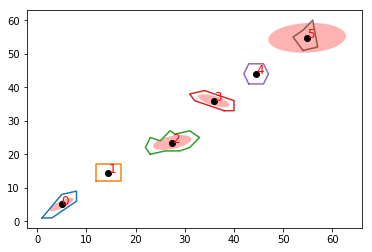

In [11]:
poly_all, regions_all = create_polygons()

# Draw the (incomplete) polygons
#for r in regions_all:
#    plt.plot(poly_all[r,0], poly_all[r,1])
plot_full_polygons(regions_all, poly_all)    
fit_ellipses_to_cells(regions_all, poly_all)
plt.show()

/home/sam/anaconda3/envs/env/lib/python3.6/site-packages/ipykernel_launcher.py:36: RuntimeWarning: invalid value encountered in true_divide
/home/sam/anaconda3/envs/env/lib/python3.6/site-packages/ipykernel_launcher.py:38: RuntimeWarning: divide by zero encountered in true_divide
/home/sam/anaconda3/envs/env/lib/python3.6/site-packages/ipykernel_launcher.py:39: RuntimeWarning: divide by zero encountered in true_divide
/home/sam/anaconda3/envs/env/lib/python3.6/site-packages/ipykernel_launcher.py:34: RuntimeWarning: invalid value encountered in true_divide


xxxxxxxxxxxxxxxxxxxx
Delta : [136.94683613   0.         299.88961212 163.75429763  29.
  64.8684504 ]
xxxxxxxxxxxxxxxxxxxx
Semi minor before sqrt : 
 [ 0.89655301         inf  3.53285196 -1.83675121         inf 19.50333478]
xxxxxxxxxxxxxxxxxxxx
Semi major before sqrt : 
 [  9.12221719          inf  16.52598927 -12.03572771          inf
  62.6735103 ]
xxxxxxxxxxxxxxxxxxxx
Semi minor after abs : 
 [ 0.89655301         inf  3.53285196  1.83675121         inf 19.50333478]
xxxxxxxxxxxxxxxxxxxx
Semi major after abs : 
 [ 9.12221719         inf 16.52598927 12.03572771         inf 62.6735103 ]
xxxxxxxxxxxxxxxxxxxx
Angles after abs : 
 [ 0.6680088          nan  0.33164312 -0.450858    0.          0.09319525]
xxxxxxxxxxxxxxxxxxxx
Semi minor after sqrt : 
 [0.94686483        inf 1.87958824 1.35526795        inf 4.41625801]
xxxxxxxxxxxxxxxxxxxx
Semi major after sqrt : 
 [3.02030084        inf 4.065217   3.46925463        inf 7.9166603 ]
xxxxxxxxxxxxxxxxxxxx
Delta : [136.94683613   0.         299.8

xxxxxxxxxxxxxxxxxxxx
Delta : [  6.66584357  21.14924973 238.24521379  56.18284084  51.48428168
 110.23898226]
xxxxxxxxxxxxxxxxxxxx
Semi minor before sqrt : 
 [-0.48019336 11.46318209 -1.86035244 -9.91848108  7.27784275  1.99131274]
xxxxxxxxxxxxxxxxxxxx
Semi major before sqrt : 
 [-31.78067621  23.58161008 -11.82439649 -43.62818559  15.5643523
  10.30319347]
xxxxxxxxxxxxxxxxxxxx
Semi minor after abs : 
 [ 0.48019336 11.46318209  1.86035244  9.91848108  7.27784275  1.99131274]
xxxxxxxxxxxxxxxxxxxx
Semi major after abs : 
 [31.78067621 23.58161008 11.82439649 43.62818559 15.5643523  10.30319347]
xxxxxxxxxxxxxxxxxxxx
Angles after abs : 
 [-0.12922747  0.36051031 -0.4660611  -0.11980325  0.65353361  0.6479949 ]
xxxxxxxxxxxxxxxxxxxx
Semi minor after sqrt : 
 [0.69295985 3.38573214 1.36394737 3.14936201 2.69774772 1.41113881]
xxxxxxxxxxxxxxxxxxxx
Semi major after sqrt : 
 [5.63743525 4.85609    3.43866202 6.60516355 3.94516822 3.20985879]
xxxxxxxxxxxxxxxxxxxx
Delta : [  6.66584357  21.1492497

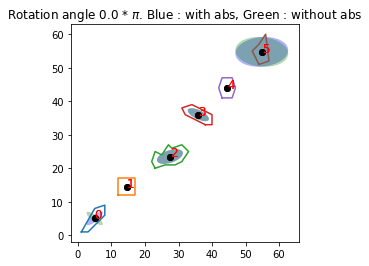

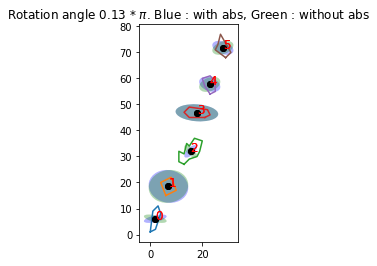

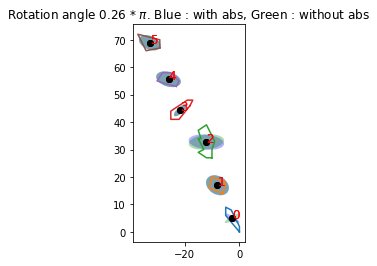

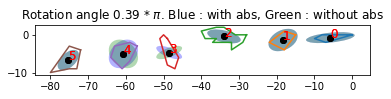

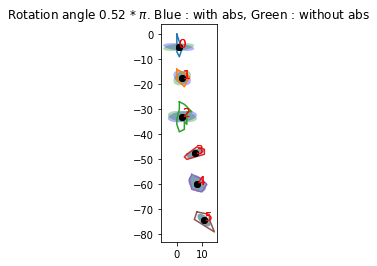

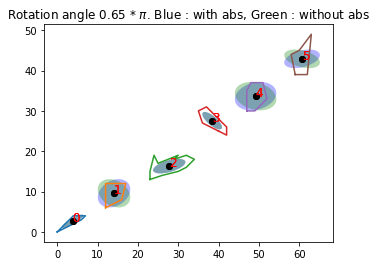

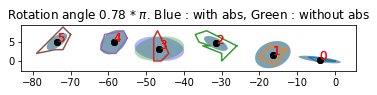

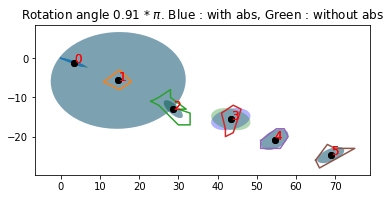

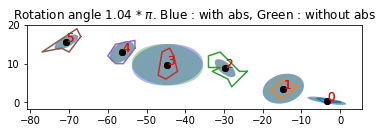

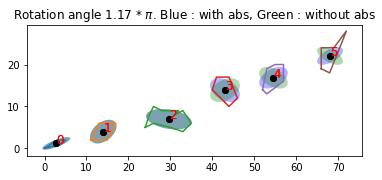

In [12]:
#%matplotlib notebook
### Try different rotations
poly_all, regions_all = create_polygons()
range_to_study = np.arange(0.0, 1.25, 0.13)
for rotation_factor in range_to_study:
    # Rotate the polygons
    angle_to_rotate = np.pi * rotation_factor
    poly_rot_all = poly_all
    for index, point in enumerate(poly_rot_all):
        poly_rot_all[index] = np.matmul(rotation_matrix(angle_to_rotate), point)

    # Draw the (incomplete) polygons
    plt.figure()
    plt.title("Rotation angle {} * $\pi$. Blue : with abs, Green : without abs".format(rotation_factor))
    plot_full_polygons(regions_all, poly_all)
    fit_ellipses_to_cells(regions_all, poly_rot_all, debug=True)
    plt.axis('scaled')
#    plt.savefig("poly_rot_pi_x_{}_with_and_without_abs.png".format(rotation_factor))
    
    

xxxxxxxxxxxxxxxxxxxx
Delta : [  2.34856872  28.59583294 229.77786417  56.54338787  52.77131683
  78.33831139]
xxxxxxxxxxxxxxxxxxxx
Semi minor before sqrt : 
 [  1.00709156 -10.14471399  -3.49262994  -5.47552121  20.75569762
   1.85957565]
xxxxxxxxxxxxxxxxxxxx
Semi major before sqrt : 
 [ 11.15290844 -26.4563245  -19.84635832 -13.96495486  64.62582848
  10.33207293]
xxxxxxxxxxxxxxxxxxxx
Semi minor after abs : 
 [ 1.00709156 10.14471399  3.49262994  5.47552121 20.75569762  1.85957565]
xxxxxxxxxxxxxxxxxxxx
Semi major after abs : 
 [11.15290844 26.4563245  19.84635832 13.96495486 64.62582848 10.33207293]
xxxxxxxxxxxxxxxxxxxx
Angles after abs : 
 [ 0.45418502 -0.25630199 -0.25557758 -0.61478935  0.09169126  0.61762665]
xxxxxxxxxxxxxxxxxxxx
Semi minor after sqrt : 
 [1.00353952 3.18507676 1.86885792 2.33998316 4.55584214 1.36366259]
xxxxxxxxxxxxxxxxxxxx
Semi major after sqrt : 
 [3.33959705 5.14357118 4.45492518 3.73697135 8.03901912 3.2143542 ]


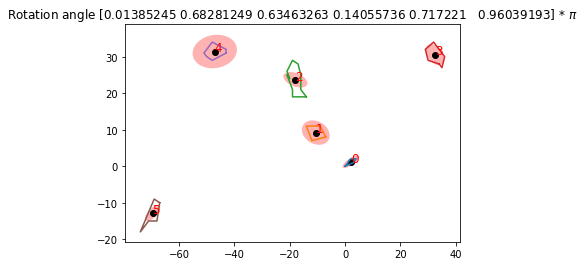

In [13]:
### Shift every polygon with a different angle
poly_all, regions_all = create_polygons()
#np.random.seed(10)
rotation_factor = np.random.rand(len(regions_all))
curr_pos = 0
plt.figure()
for index,rot_factor in enumerate(rotation_factor):
    angle_to_rotate = np.pi * rot_factor
    for i, point in enumerate(poly_rot_all[regions_all[index]]):
        # Careful, this assumes that vertices and regions are ordered 
        poly_rot_all[curr_pos + i] = np.matmul(rotation_matrix(angle_to_rotate), point)
        
    curr_pos += len(regions_all[index])
        
#    plt.savefig("poly_rot_pi_x_{}.png".format(rotation_factor))

fit_ellipses_to_cells(regions_all, poly_rot_all)
plot_full_polygons(regions_all, poly_rot_all)
plt.title("Rotation angle {} * $\pi$".format(rotation_factor))
plt.show()

xxxxxxxxxxxxxxxxxxxx
Delta : [6.94062751e+02 4.70270223e+01 1.87596287e+03 4.00487295e+03
 7.34901801e+03 4.69860395e+02 6.46576887e+01 1.55574383e+03
 4.45700148e+03 6.06338764e+03 8.74257653e+02 1.23806695e+03
 6.69407024e+02 3.28986216e+04 2.03290790e+03 3.84239654e+03
 6.65891627e+03 2.21584845e+03 9.46994952e+03 9.57598927e+03
 1.03142317e+04 7.54509356e+03 1.46252701e+03 6.20658996e+03
 4.89255455e+02 1.10748836e+03 1.16354014e+03 1.27406882e+03
 6.56203123e+03 8.37125476e+02 2.21987788e+03 2.80398395e+03
 1.62094707e+02 2.62683295e+02 3.89812672e+03 5.66158386e+03
 4.85098180e+02 5.00786714e+03 4.71714478e+03 2.06731308e+04
 3.98730714e+03 4.64676213e+02 6.11094218e+02 8.19035251e+03
 7.52649632e+03 4.01421343e+02 1.04552592e+03 1.99080686e+02
 5.16123550e+02 1.17061260e+03 6.94062751e+02 2.13863916e+03
 1.07707555e+04 4.00487295e+03 8.14732325e+03 3.16286686e+04
 6.46576887e+01 1.55574383e+03 4.45700148e+03 6.06338764e+03
 1.04111620e+03 1.23806695e+03 6.69407024e+02 3.28986216

Semi major after sqrt : 
 [ 2.49489559 10.42280399  3.59408097  9.91871771  4.97984569  7.16710332
  3.23945278  4.7445211   4.43050012  3.18777187  1.8687674  18.58237611
  5.2552909  13.38781336  2.97943074  4.06327887  3.78714515 12.12648603
  4.36814828  3.56205488  2.30661899  2.37682879 12.68438208  3.95054788
  1.75836228  3.53368001  1.97872903  6.07979668  3.56195023  1.97954387
  1.70951788  3.87434578  3.50536901  2.00005134  4.1881168   2.02857828
  5.68053188  4.6998588   6.50449017  4.23935334  5.06382563  4.09092549
  3.56165914  3.76795984  3.1191353   2.7839514   5.36701368  1.92234539
  6.16411174  1.03325591  2.49489559  4.65151141  3.46351902 11.27947246
  5.65932806 12.64450066  3.23945278  4.7445211   5.35479147  4.29976794
  3.66492767 18.58237611  5.2552909   8.96957255  2.97943074  2.83384427
  2.88896262 12.12648603  2.56445747  2.16434088  5.13974067  2.37682879
 12.68438208  2.67757003  3.35562766  3.53368001  3.75258965  4.76720344
  3.56195023  1.97954387 

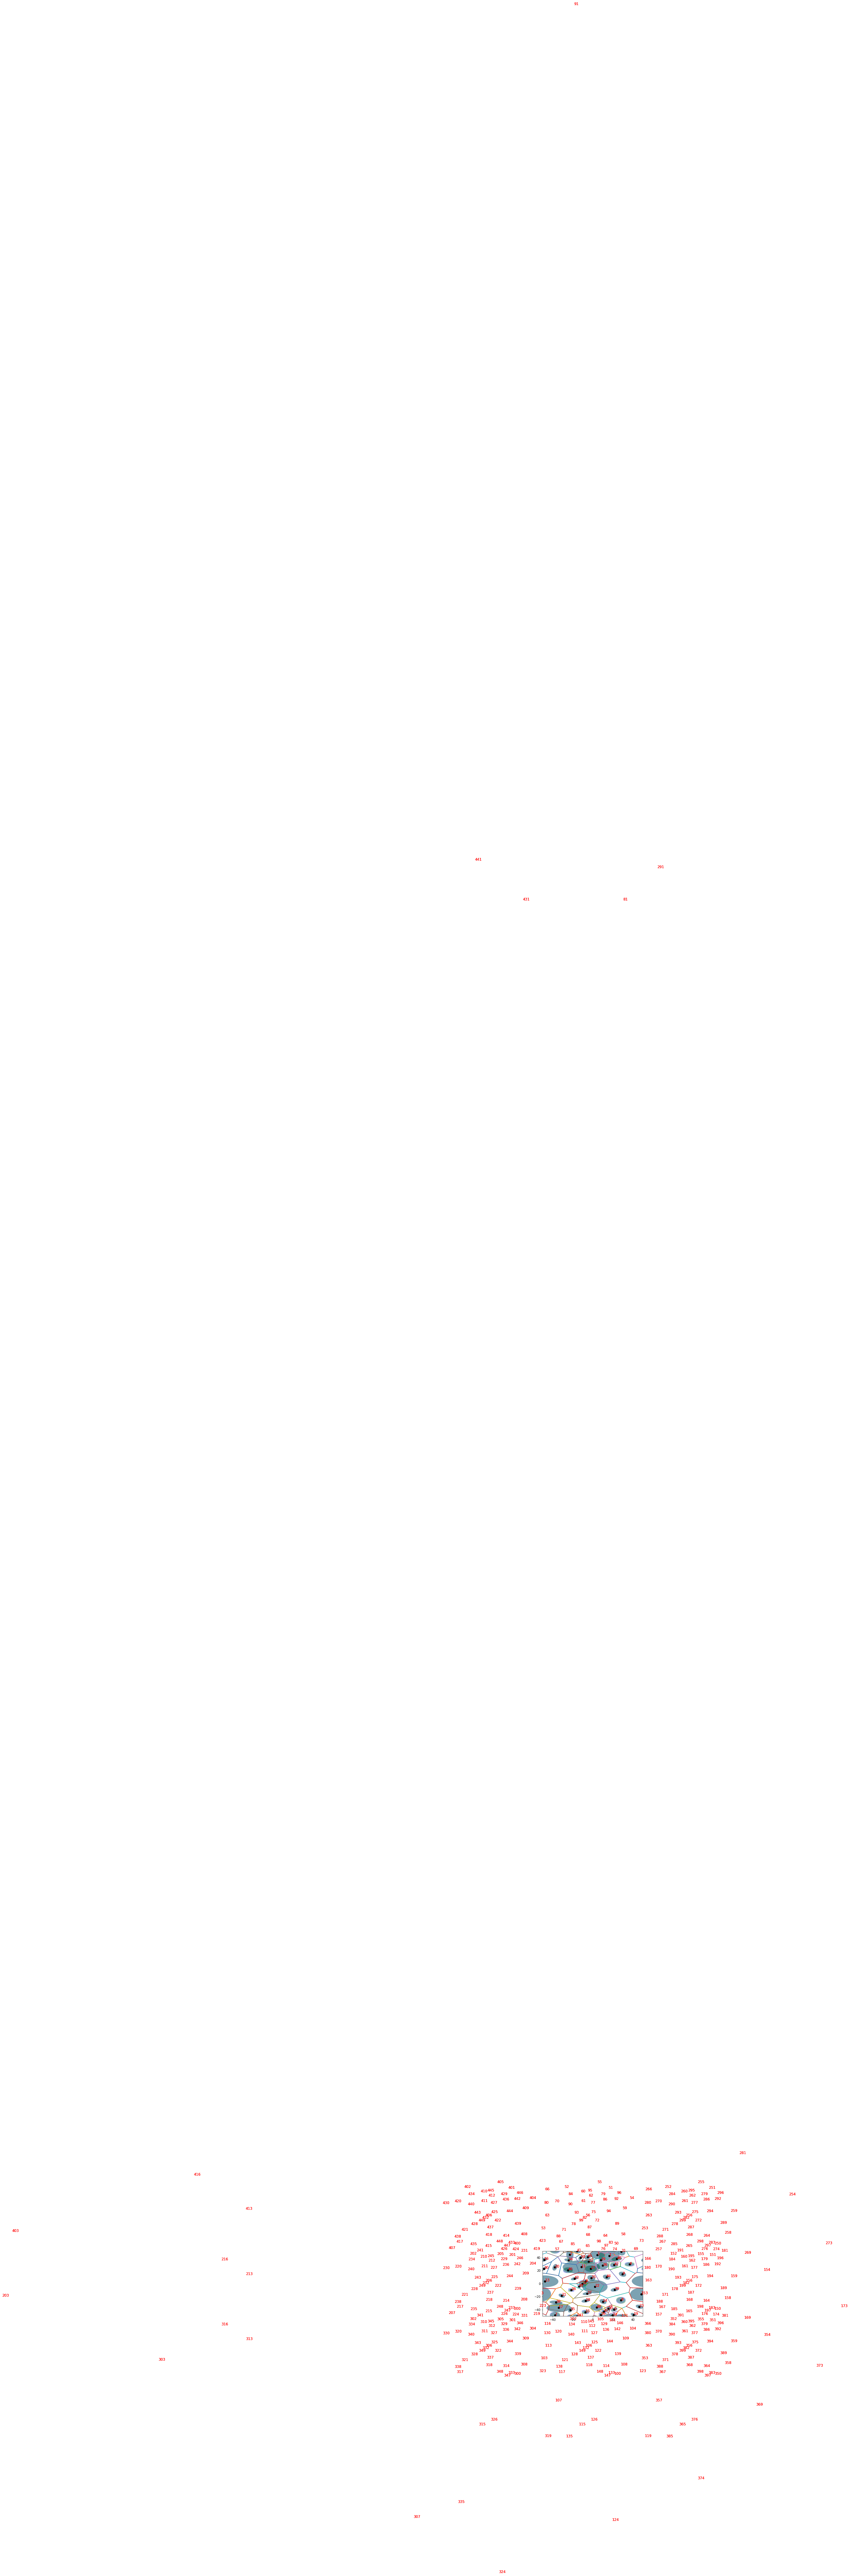

In [14]:
boxsize = 100
#np.random.seed(29308)
np.random.seed(4876)
points = initialization(50,boxsize)
points = np.asarray(generate_periodic_voronoi_cells_2(points,boxsize))

vor = Voronoi(points)
regions, vertices = voronoi_finite_polygons_2d(vor, boxsize)
index, perimeters, areas = get_polygons_properties_2d(regions, vertices)

plot_full_polygons(regions,vertices)
plt.xlim(-boxsize/2.0, boxsize/2.0)
plt.ylim(-boxsize/2.0, boxsize/2.0)

fit_ellipses_to_cells(regions, vertices, debug=True)
plt.show()
#plt.savefig('test_debug.png')